# Final results — every fully-retrained candidate

Phase 5.2's comparison table/chart: every candidate that was actually
distilled (fixed-loss schedule) and evaluated on the full 159-problem
HumanEval-TS suite, params vs.\ accuracy, plus real serving
throughput/latency for the subset that got inference-engine benchmarks
(`docs/debug/phase4_inference_benchmark_summary.json`). No GPU needed --
this loads and consolidates results already measured and archived
elsewhere; it does not run anything new.

In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")

# (name, family, docs/debug prefix, approx params in B) -- params from the
# project's per-layer param formula (plan.md), same values already in
# docs/latex/main.tex's tables. family in {"baseline", "experts-only",
# "depth-only", "combined"}.
CANDIDATES = [
    ("baseline", "baseline", "phase4_baseline_humaneval_ts_full159", 30.50),
    ("experts112", "experts-only", "phase4_pure_axis_depth0_experts112_fixedloss_short", 5.15),
    ("experts97", "experts-only", "phase4_depth0_experts97_fixedloss_short", 8.55),
    ("experts64", "experts-only", "phase4_pure_axis_depth0_experts64_fixedloss_short", 16.03),
    ("experts60", "experts-only", "phase4_depth0_experts60_fixedloss_short", 16.94),
    ("experts32", "experts-only", "phase4_pure_axis_depth0_experts32_fixedloss_short", 23.28),
    ("experts16", "experts-only", "phase4_pure_axis_depth0_experts16_fixedloss_short", 26.91),
    ("experts8", "experts-only", "phase4_pure_axis_depth0_experts8_fixedloss_short", 28.72),
    ("depth24/experts0", "depth-only", "phase4_pure_axis_depth24_experts0_fixedloss_short", 15.58),
    ("depth16/experts0", "depth-only", "phase4_pure_axis_depth16_experts0_fixedloss_short", 20.56),
    ("depth22/experts92", "combined", "phase4_depth22_experts92_fixedloss_short", 5.53),
    (
        "aggressive depth16/experts80",
        "combined",
        "phase4_aggressive_depth_experts_fixedloss_short",
        8.48,
    ),
    ("depth12/experts80", "combined", "phase4_depth12_experts80_rawfile_fixedloss", 9.46),
]


def load_full_pass_at_1(prefix: str) -> float:
    metrics = json.loads((DEBUG / f"{prefix}_humaneval_ts_full.json").read_text())
    assert metrics["config"]["limit"] is None, prefix
    return metrics["multiple-ts"]["pass@1"]


baseline_pass_at_1 = load_full_pass_at_1("phase4_baseline_humaneval_ts_full159")

results = []
for name, family, prefix, params_b in CANDIDATES:
    pass_at_1 = load_full_pass_at_1(prefix)
    results.append(
        {
            "candidate": name,
            "family": family,
            "params_b": params_b,
            "pass_at_1": pass_at_1,
            "n_correct": round(pass_at_1 * 159),
            "pct_of_baseline_params": round(100 * params_b / 30.50, 1),
            "pct_of_baseline_accuracy": round(100 * pass_at_1 / baseline_pass_at_1, 1),
        }
    )

results.sort(key=lambda r: r["params_b"])
results

[{'candidate': 'experts112',
  'family': 'experts-only',
  'params_b': 5.15,
  'pass_at_1': 0.08176100628930817,
  'n_correct': 13,
  'pct_of_baseline_params': 16.9,
  'pct_of_baseline_accuracy': 11.4},
 {'candidate': 'depth22/experts92',
  'family': 'combined',
  'params_b': 5.53,
  'pass_at_1': 0.06918238993710692,
  'n_correct': 11,
  'pct_of_baseline_params': 18.1,
  'pct_of_baseline_accuracy': 9.6},
 {'candidate': 'aggressive depth16/experts80',
  'family': 'combined',
  'params_b': 8.48,
  'pass_at_1': 0.20754716981132076,
  'n_correct': 33,
  'pct_of_baseline_params': 27.8,
  'pct_of_baseline_accuracy': 28.9},
 {'candidate': 'experts97',
  'family': 'experts-only',
  'params_b': 8.55,
  'pass_at_1': 0.2830188679245283,
  'n_correct': 45,
  'pct_of_baseline_params': 28.0,
  'pct_of_baseline_accuracy': 39.5},
 {'candidate': 'depth12/experts80',
  'family': 'combined',
  'params_b': 9.46,
  'pass_at_1': 0.3018867924528302,
  'n_correct': 48,
  'pct_of_baseline_params': 31.0,
  'pct

## Accuracy vs. parameters, by pruning axis

All 13 fully-retrained candidates, grouped by which axis (or combination)
was pruned, against the reconciled baseline.

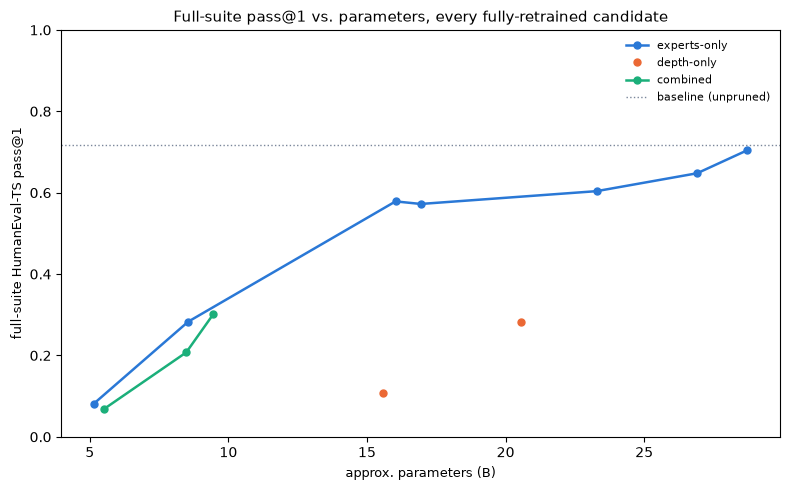

In [2]:
from bonsai.pruning.viz import plot_axis_isolation

series = {}
for family in ("experts-only", "depth-only", "combined"):
    rows = [r for r in results if r["family"] == family]
    rows.sort(key=lambda r: r["params_b"])
    series[family] = (
        [r["params_b"] for r in rows],
        [r["pass_at_1"] for r in rows],
    )

fig = plot_axis_isolation(
    series,
    baseline_pass_at_1=baseline_pass_at_1,
    title="Full-suite pass@1 vs. parameters, every fully-retrained candidate",
)
fig.savefig("../docs/latex/figures/phase4_final_results.png", dpi=150)
fig.savefig("../docs/latex/figures/phase4_final_results.pdf")

## Accuracy + real serving throughput, for the benchmarked subset

Only 4 of the 13 candidates got real vLLM/SGLang serving benchmarks
(`docs/debug/phase4_inference_benchmark_summary.json`, concurrency 16,
512 fixed output tokens -- see `sec:inference-benchmark` in the paper).
This is the actual deployment-decision table: params, accuracy, and
measured throughput side by side, not just a parameter-count proxy for
serving cost.

In [3]:
inf_summary = json.loads((DEBUG / "phase4_inference_benchmark_summary.json").read_text())
inf_rows = inf_summary["rows"]

BENCHMARKED = {
    "baseline": "baseline",
    "experts64": "depth0_experts64",
    "depth16/experts0": "depth16_experts0",
    "experts8": "depth0_experts8",
}


def inf_row(slug: str, engine: str) -> dict:
    for r in inf_rows:
        if r["candidate"] == slug and r["engine"] == engine and r["concurrency"] == 16:
            return r
    raise KeyError((slug, engine))


deployment_table = []
for r in results:
    if r["candidate"] not in BENCHMARKED:
        continue
    slug = BENCHMARKED[r["candidate"]]
    vllm = inf_row(slug, "vllm")
    sglang = inf_row(slug, "sglang")
    deployment_table.append(
        {
            "candidate": r["candidate"],
            "params_b": r["params_b"],
            "pass_at_1": r["pass_at_1"],
            "pct_of_baseline_accuracy": r["pct_of_baseline_accuracy"],
            "vllm_tok_s": vllm["throughput_tok_s"],
            "sglang_tok_s": sglang["throughput_tok_s"],
        }
    )

deployment_table.sort(key=lambda r: r["params_b"])
deployment_table

[{'candidate': 'experts64',
  'params_b': 16.03,
  'pass_at_1': 0.5786163522012578,
  'pct_of_baseline_accuracy': 80.7,
  'vllm_tok_s': 2985.7486881234026,
  'sglang_tok_s': 3253.6305860488633},
 {'candidate': 'depth16/experts0',
  'params_b': 20.56,
  'pass_at_1': 0.2830188679245283,
  'pct_of_baseline_accuracy': 39.5,
  'vllm_tok_s': 3660.5381434176124,
  'sglang_tok_s': 3935.4818275223643},
 {'candidate': 'experts8',
  'params_b': 28.72,
  'pass_at_1': 0.7044025157232704,
  'pct_of_baseline_accuracy': 98.2,
  'vllm_tok_s': 2535.4448992854227,
  'sglang_tok_s': 2730.525717501455},
 {'candidate': 'baseline',
  'params_b': 30.5,
  'pass_at_1': 0.7169811320754716,
  'pct_of_baseline_accuracy': 100.0,
  'vllm_tok_s': 2545.6237752874954,
  'sglang_tok_s': 2689.9590198812984}]